# 1. Problem Statement

The telco customer churn dataset is a set of data gathered from an internet provider company and was found on kaggle at the following link: https://www.kaggle.com/datasets/blastchar/telco-customer-churn. The dataset is on the shorter end, consisting of 7043 rows with 21 columns. This dataset shows various customer behavior and the different services that they recieved from the company. The dataset also tracks if the customer renewed their subscription at the end of the month. The problem that this dataset aims to solve is how often customers are to renew their subscription with the internet provider.

The target variable in this dataset is the churn column and churn represents customers who left within the last month. The churn column uses the value "yes" to indicated whether the customer has stopped using the service and uses the value "no" if the customer has continued to use the service offered by the company. The target variable is unbalanced as over five thousand entries that stayed with the provider and just under two thousand entries that left the provider at the end of the month. My prediction goal for this dataset is to accurately predict whether a customer will leave the provider based on the services that they used. This could be used to identify weaknesses in specific services that the company offers that are driving customers away. 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [2]:
print("Dataset Shape:", df.shape)

Dataset Shape: (7043, 21)


In [3]:
print("Columns:", df.columns)

Columns: Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


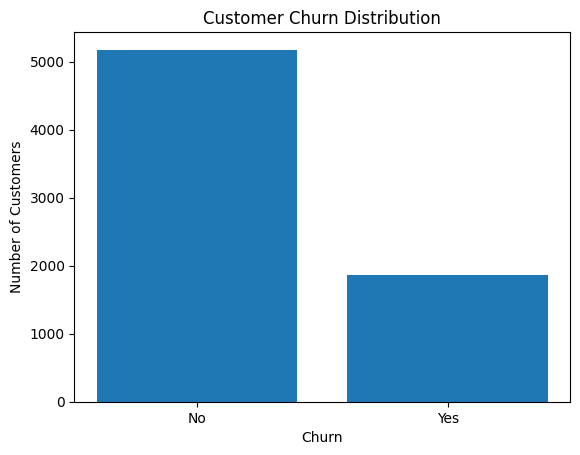

In [6]:
churn_counts = df["Churn"].value_counts()

plt.bar(churn_counts.index, churn_counts.values)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

# 2. Basic Data Cleaning

### Drop Unwanted Features

In [7]:
df = df.drop(columns=["customerID"])

print(df.shape)

(7043, 20)


We drop the column that uniquely identifies each customer as it offers no value when predicting if the customer stays with the provider or not. 

### Check Missing Values

In [8]:
object_columns = df.select_dtypes(include=["object"]).columns

for column in object_columns:
    blank_count = (df[column].str.strip() == "").sum()

    print(f"{column}: {blank_count} blank values")

print((df["TotalCharges"].str.strip() == "").sum())

gender: 0 blank values
Partner: 0 blank values
Dependents: 0 blank values
PhoneService: 0 blank values
MultipleLines: 0 blank values
InternetService: 0 blank values
OnlineSecurity: 0 blank values
OnlineBackup: 0 blank values
DeviceProtection: 0 blank values
TechSupport: 0 blank values
StreamingTV: 0 blank values
StreamingMovies: 0 blank values
Contract: 0 blank values
PaperlessBilling: 0 blank values
PaymentMethod: 0 blank values
TotalCharges: 11 blank values
Churn: 0 blank values
11


In [9]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

print(df.isnull().sum())

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [10]:
df = df.dropna(subset=["TotalCharges"])

print("Remaining rows:", len(df))

Remaining rows: 7032


In [11]:
print(df.isnull().sum())

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


### Remove Duplicates

In [12]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 22


In [13]:
df = df.drop_duplicates()

print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


### Check Categorical Variables for Inconsistent Inputs

In [14]:
categorical_columns = df.select_dtypes(
    include=["object"]
).columns

for column in categorical_columns:
    print(f"{column}: {df[column].unique()}")

gender: ['Female' 'Male']
Partner: ['Yes' 'No']
Dependents: ['No' 'Yes']
PhoneService: ['No' 'Yes']
MultipleLines: ['No phone service' 'No' 'Yes']
InternetService: ['DSL' 'Fiber optic' 'No']
OnlineSecurity: ['No' 'Yes' 'No internet service']
OnlineBackup: ['Yes' 'No' 'No internet service']
DeviceProtection: ['No' 'Yes' 'No internet service']
TechSupport: ['No' 'Yes' 'No internet service']
StreamingTV: ['No' 'Yes' 'No internet service']
StreamingMovies: ['No' 'Yes' 'No internet service']
Contract: ['Month-to-month' 'One year' 'Two year']
PaperlessBilling: ['Yes' 'No']
PaymentMethod: ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn: ['No' 'Yes']


Each category has consistent outputs following an output from a list of 2 or 3 options.

In [15]:
for column in categorical_columns:
    df[column] = df[column].str.strip()

### Transform Categorical Variables into Numeric

In [16]:
df['gender'] = df['gender'].map({'Male': 1, 'Female': 0})
df['Partner'] = df['Partner'].map({'Yes': 1, 'No': 0})
df['Dependents'] = df['Dependents'].map({'Yes': 1, 'No': 0})
df['PhoneService'] = df['PhoneService'].map({'Yes': 1, 'No': 0})
df['PaperlessBilling'] = df['PaperlessBilling'].map({'Yes': 1, 'No': 0})
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

In [17]:
# Multiple categories
df['MultipleLines'] = df['MultipleLines'].map({
    'No phone service': 0,
    'No': 1,
    'Yes': 2
})

df['InternetService'] = df['InternetService'].map({
    'No': 0,
    'DSL': 1,
    'Fiber optic': 2
})

df['OnlineSecurity'] = df['OnlineSecurity'].map({
    'No internet service': 0,
    'No': 1,
    'Yes': 2
})

df['OnlineBackup'] = df['OnlineBackup'].map({
    'No internet service': 0,
    'No': 1,
    'Yes': 2
})

df['DeviceProtection'] = df['DeviceProtection'].map({
    'No internet service': 0,
    'No': 1,
    'Yes': 2
})

df['TechSupport'] = df['TechSupport'].map({
    'No internet service': 0,
    'No': 1,
    'Yes': 2
})

df['StreamingTV'] = df['StreamingTV'].map({
    'No internet service': 0,
    'No': 1,
    'Yes': 2
})

df['StreamingMovies'] = df['StreamingMovies'].map({
    'No internet service': 0,
    'No': 1,
    'Yes': 2
})

df['Contract'] = df['Contract'].map({
    'Month-to-month': 0,
    'One year': 1,
    'Two year': 2
})

df['PaymentMethod'] = df['PaymentMethod'].map({
    'Electronic check': 0,
    'Mailed check': 1,
    'Bank transfer (automatic)': 2,
    'Credit card (automatic)': 3
})

### Use Boxplots to Identify Outlier

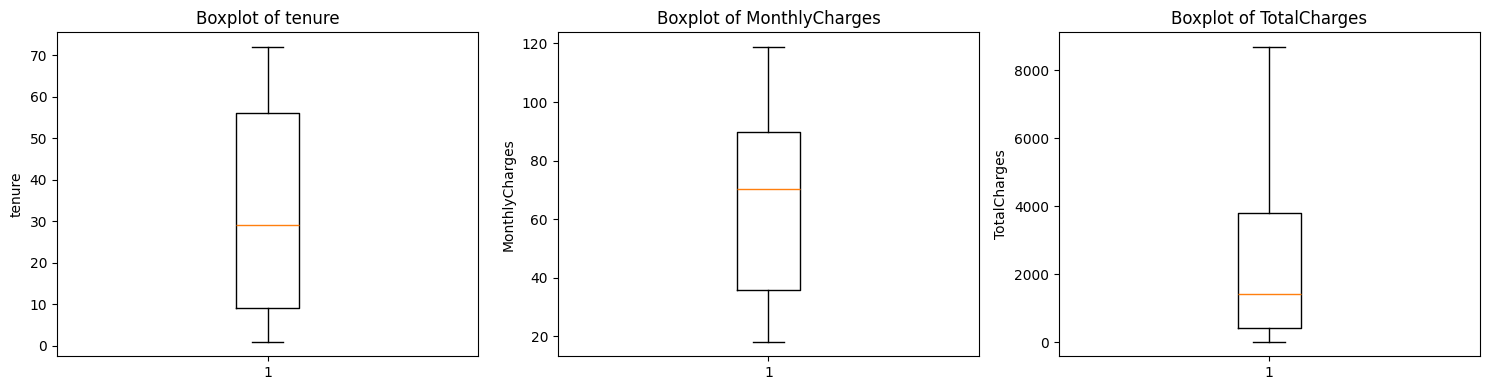

In [18]:
numeric_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, column in enumerate(numeric_columns):
    axes[i].boxplot(df[column])
    axes[i].set_title(f"Boxplot of {column}")
    axes[i].set_ylabel(column)

# Adjust spacing between plots
plt.tight_layout()
plt.show()

We only analzye the numerical value columns which are TotalCharges, MonthlyCharges, and Tenure

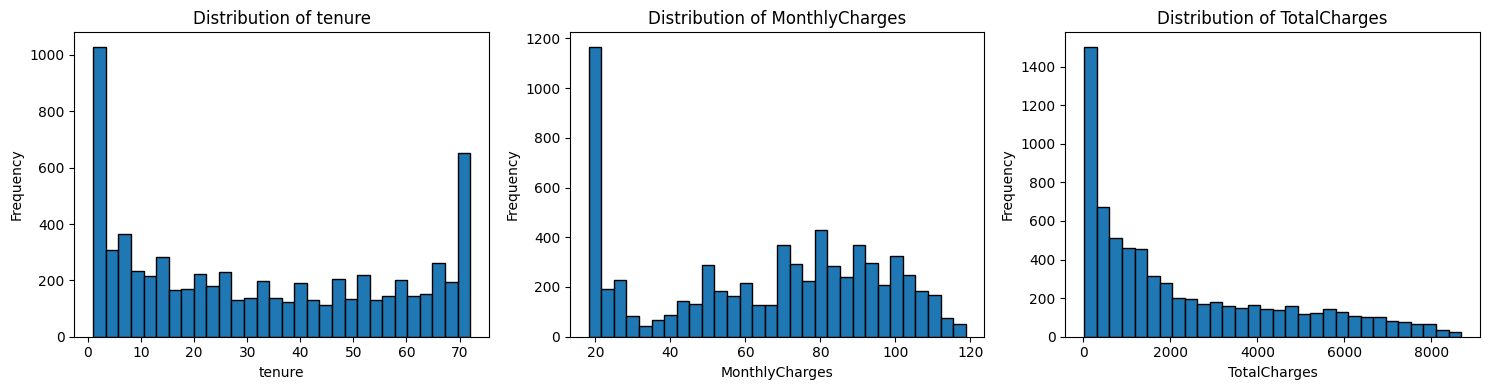

In [19]:
numeric_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Create one row with three histograms
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, column in enumerate(numeric_columns):
    axes[i].hist(df[column], bins=30, edgecolor="black")

    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [20]:
df_no_outliers = df.copy()

for column in numeric_columns:

    Q1 = df_no_outliers[column].quantile(0.25)
    Q3 = df_no_outliers[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df_no_outliers[column] < lower_bound) |
        (df_no_outliers[column] > upper_bound)
    )

    print(f"{column}: {outliers.sum()} outliers")

    df_no_outliers = df_no_outliers[~outliers]

tenure: 0 outliers
MonthlyCharges: 0 outliers
TotalCharges: 0 outliers


According to the graphs above and the IQR calculation, there are no noticable outliers within the dataset.

### Verifying that the Dataset is Cleaned

In [21]:
print("Cleaned Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Cleaned Dataset Shape: (7010, 20)

Missing Values:
0

Duplicate Rows:
0

Data Types:
gender                int64
SeniorCitizen         int64
Partner               int64
Dependents            int64
tenure                int64
PhoneService          int64
MultipleLines         int64
InternetService       int64
OnlineSecurity        int64
OnlineBackup          int64
DeviceProtection      int64
TechSupport           int64
StreamingTV           int64
StreamingMovies       int64
Contract              int64
PaperlessBilling      int64
PaymentMethod         int64
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object


# 3. Feature Engineering

### Feature Selection

In [22]:
X = df.drop(columns=['Churn'])

y = df['Churn']

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

NameError: name 'sns' is not defined

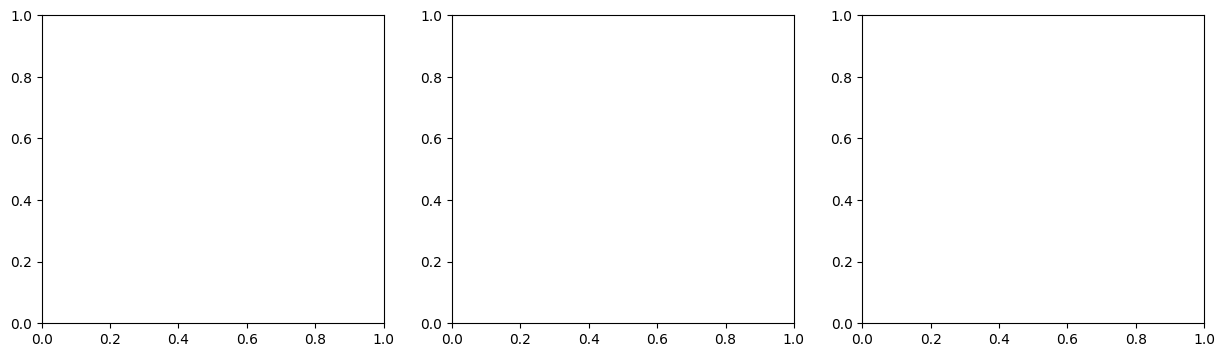

In [24]:
numeric_columns = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, column in enumerate(numeric_columns):
    sns.boxplot(
        x=y_train,
        y=X_train[column],
        ax=axes[i]
    )

    axes[i].set_title(f'{column} vs Churn')
    axes[i].set_xlabel('Churn')
    axes[i].set_ylabel(column)

plt.tight_layout()
plt.show()

In [ ]:
categorical_columns = [
    'gender',
    'SeniorCitizen',
    'Partner',
    'Dependents',
    'PhoneService',
    'MultipleLines',
    'InternetService',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
    'Contract',
    'PaperlessBilling',
    'PaymentMethod'
]

fig, axes = plt.subplots(4, 4, figsize=(20, 16))

for i, column in enumerate(categorical_columns):
    sns.countplot(
        x=X_train[column],
        hue=y_train,
        ax=axes.flat[i]
    )

    axes.flat[i].set_title(f'{column} vs Churn')
    axes.flat[i].set_xlabel(column)
    axes.flat[i].set_ylabel('Count')

plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(20, 16))

for i, column in enumerate(categorical_columns):

    churn_rates = pd.DataFrame({
        column: X_train[column],
        'Churn': y_train
    }).groupby(column)['Churn'].mean() * 100

    churn_rates.plot(
        kind='bar',
        ax=axes.flat[i]
    )

    axes.flat[i].set_title(f'{column} Churn Rate')
    axes.flat[i].set_xlabel(column)
    axes.flat[i].set_ylabel('Churn Rate (%)')
    axes.flat[i].set_ylim(0, 100)
    axes.flat[i].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
import seaborn as sns

correlation_matrix = X_train.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [25]:
churn_correlations = X_train.corrwith(y_train)

churn_correlations = churn_correlations.reindex(
    churn_correlations.abs().sort_values(ascending=False).index
)

print(churn_correlations)

Contract           -0.393702
tenure             -0.344066
InternetService     0.319671
PaymentMethod      -0.266990
MonthlyCharges      0.197180
PaperlessBilling    0.194910
TotalCharges       -0.190578
Dependents         -0.168416
StreamingTV         0.166046
StreamingMovies     0.161774
SeniorCitizen       0.159496
Partner            -0.151358
DeviceProtection    0.082680
OnlineBackup        0.076237
MultipleLines       0.045127
TechSupport         0.024263
OnlineSecurity      0.022675
PhoneService        0.013230
gender              0.003778
dtype: float64


In [26]:
from sklearn.feature_selection import f_classif

numeric_columns = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

# Perform ANOVA
f_scores, p_values = f_classif(
    X_train[numeric_columns],
    y_train
)

# Display results
anova_results = pd.DataFrame({
    'Feature': numeric_columns,
    'F-Score': f_scores,
    'P-Value': p_values
})

print(anova_results.sort_values('P-Value'))

          Feature     F-Score        P-Value
0          tenure  752.760173  1.294296e-155
1  MonthlyCharges  226.777892   2.861560e-50
2    TotalCharges  211.282618   5.122644e-47


In [27]:
from sklearn.feature_selection import SelectKBest, chi2

categorical_columns = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents',
    'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod'
]

x = X_train[categorical_columns]
y = y_train

chi = SelectKBest(score_func=chi2, k='all')
catFeatures = chi.fit(x, y)

chi_results = pd.DataFrame({
    'Feature': categorical_columns,
    'Chi-Square': catFeatures.scores_,
    'P-Value': catFeatures.pvalues_
})

print(chi_results.sort_values('P-Value'))

             Feature  Chi-Square        P-Value
13          Contract  875.254044  2.351676e-192
15     PaymentMethod  403.168695   1.125010e-89
6    InternetService  278.645576   1.481669e-62
1      SeniorCitizen  119.486927   8.193354e-28
3         Dependents  111.441296   4.736240e-26
14  PaperlessBilling   85.667517   2.128813e-20
11       StreamingTV   74.466904   6.166341e-18
12   StreamingMovies   70.777093   3.999542e-17
2            Partner   66.207377   4.058905e-16
9   DeviceProtection   18.186825   2.002594e-05
8       OnlineBackup   15.461492   8.420340e-05
5      MultipleLines    3.582639   5.838633e-02
10       TechSupport    1.514313   2.184821e-01
7     OnlineSecurity    1.318492   2.508629e-01
4       PhoneService    0.096265   7.563581e-01
0             gender    0.039950   8.415777e-01


The current results are dominated by the three multivalued features. These features need to be split into dummy variables. 

In [28]:
from sklearn.feature_selection import VarianceThreshold

selector = VarianceThreshold(threshold=0)

selector.fit(X_train)

zero_variance_columns = X_train.columns[
    ~selector.get_support()
]

print("Zero variance features:")
print(zero_variance_columns.tolist())

Zero variance features:
[]


There is no features with every row having the exact same value or zero variance features.

In [29]:
import numpy as np

# Calculate absolute correlations
corr_matrix = X_train.corr().abs()

# Use the upper triangle to avoid repeated pairs
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Find highly correlated pairs
high_corr = upper.stack()

high_corr = high_corr[high_corr > 0.85]

print(high_corr.sort_values(ascending=False))

InternetService  MonthlyCharges    0.904267
dtype: float64


There are two highly correlated features with a correlation of .90 being Internet Service and Monthly Charges. Because Internet Service is a multi-valued feature and Monthly Charges has a varying value as it is a customer's bill, I have choose to keep both features.

The algorithm I chose was logistic Regression as my classification algorithm. I chose Logistic Regression because the target variable and most of my feature variables use binary values (0 and 1). While logistic regression does not require standardized data, it would improve the results of the model. This is because the numerical features that do not use binary values have numerous ranges in their values. This can be apparent in features such as monthly charges and total charges as they each have numerous different charges per customer.

With many variables having multiple values, they must be split into different sub features or dummy variables. The following features are multi-valued and must be split into dummy variables: MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, and PaymentMethod.

In [30]:
#dummy variables need to be made 
df = pd.get_dummies(
    df,
    columns=[
        'MultipleLines',
        'InternetService',
        'OnlineSecurity',
        'OnlineBackup',
        'DeviceProtection',
        'TechSupport',
        'StreamingTV',
        'StreamingMovies',
        'Contract',
        'PaymentMethod'
    ],
    dtype=int
)